#### Библиотеки

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Задание 1

Введите начальное значение X [по умолчанию -3.0]: 
Введите конечное значение X [по умолчанию 3.0]: 
Введите шаг [по умолчанию 0.5]: 


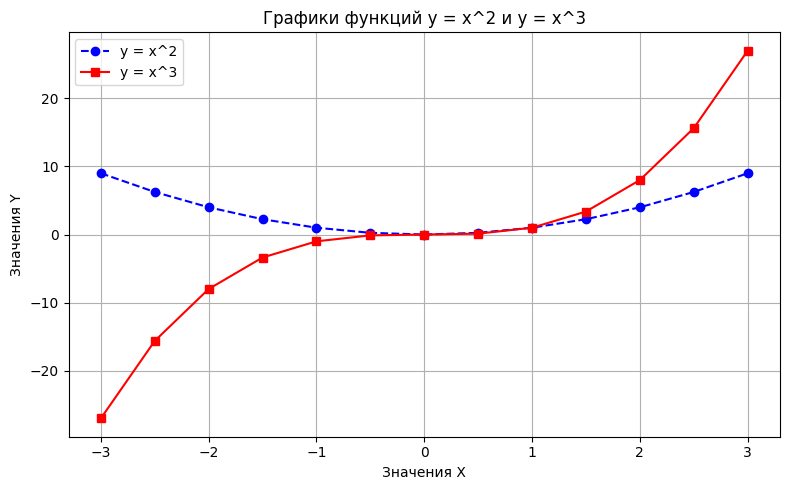

In [8]:
def get_float_input(prompt, default):
    """Запрашивает число с клавиатуры или возвращает значение по умолчанию при пустом вводе."""
    user_val = input(f"{prompt} [по умолчанию {default}]: ").strip()
    if not user_val:
        return default
    return float(user_val)


# Ввод диапазона и шага с клавиатуры (с проверкой корректности)
try:
    x_min = get_float_input("Введите начальное значение X", -3.0)
    x_max = get_float_input("Введите конечное значение X", 3.0)
    step = get_float_input("Введите шаг", 0.5)

    if step <= 0 or x_min >= x_max:
        raise ValueError("Шаг должен быть > 0, а начало диапазона < конца")
except ValueError as e:
    print(f"Ошибка ввода ({e}). Используются стандартные параметры: от -3 до 3 с шагом 0.5")
    x_min, x_max, step = -3.0, 3.0, 0.5

# Формируем массив X (добавляем небольшое число к x_max, чтобы правая граница вошла в диапазон)
x = np.arange(x_min, x_max + step / 1000, step)

# Вычисляем значения функций
y1 = x**2
y2 = x**3

# Создание полотна размером 8x5 дюймов
plt.figure(figsize=(8, 5))

# Построение графика y = x^2
plt.plot(x, y1, color="blue", linestyle="--", marker="o", label="y = x^2")

# Построение графика y = x^3
plt.plot(x, y2, color="red", linestyle="-", marker="s", label="y = x^3")

# Оформление графика
plt.title("Графики функций y = x^2 и y = x^3")
plt.xlabel("Значения X")
plt.ylabel("Значения Y")
plt.grid(True)
plt.legend(loc="upper left")

# Отображение результата
plt.tight_layout()
plt.show()

### Задание 2 (опциональное)

Для построения графика был использован датасет Kaggle -  *Student Depression Dataset*, который содержит информацию о факторах (учебная нагрузка, финансовые трудности, социальная изоляция и проблемы со здоровьем), связанных с депрессией у студентов.

In [10]:
df = pd.read_csv('Student_Depression_Dataset.csv')
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


In [12]:
df.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


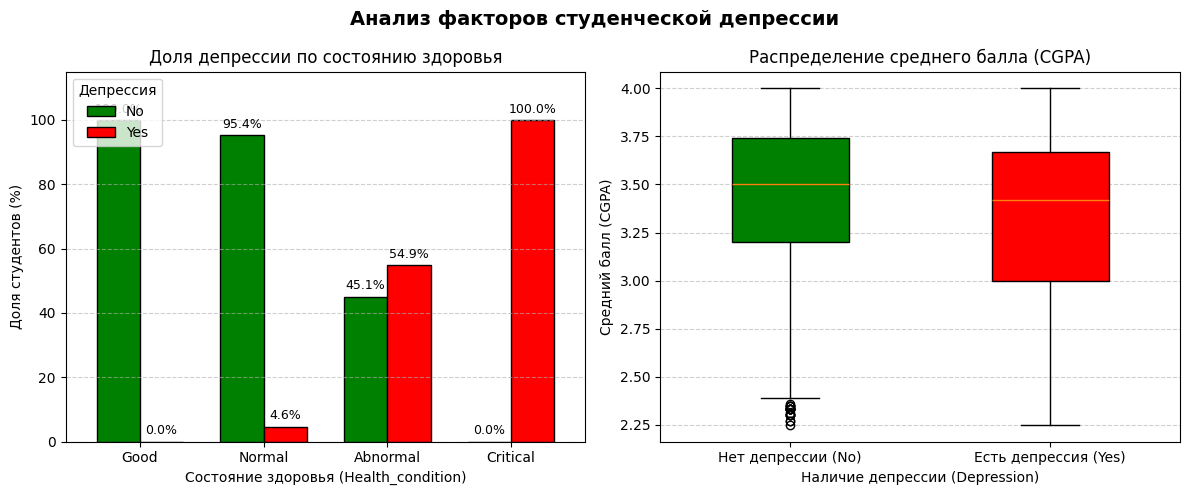

In [23]:
# Создаём полотно размером 12x5 дюймов с двумя графиками рядом
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# График 1: связь состояния здоровья и депрессии
# Считаем процент студентов с депрессией и без неё для каждой категории здоровья
counts = df.groupby(["Health_condition", "Depression"]).size().unstack()
totals = counts.sum(axis=1)
health_dep = (counts.T / totals).T * 100

# Упорядочим категории логически (если они присутствуют в данных)
order = [
    col for col in ["Good", "Normal", "Abnormal", "Critical"] if col in health_dep.index
]
if order:
    health_dep = health_dep.loc[order]

health_dep.plot(
    kind="bar",
    ax=axes[0],
    color=["green", "red"],  # Зелёный для No, красный для Yes
    edgecolor="black",
    width=0.7,
)

axes[0].set_title("Доля депрессии по состоянию здоровья", fontsize=12)
axes[0].set_xlabel("Состояние здоровья (Health_condition)")
axes[0].set_ylabel("Доля студентов (%)")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", linestyle="--", alpha=0.6)
axes[0].legend(title="Депрессия", loc="upper left")

# Добавляем подписи процентов прямо над столбцами для наглядности
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)
axes[0].set_ylim(0, 115)  # Запас сверху, чтобы цифры не упирались в рамку

# График 2: Распределение среднего балла (CGPA) и депрессия
groups = [
    df[df["Depression"] == "No"]["CGPA"].dropna(),
    df[df["Depression"] == "Yes"]["CGPA"].dropna(),
]

box = axes[1].boxplot(
    groups,
    tick_labels=["Нет депрессии (No)", "Есть депрессия (Yes)"],
    patch_artist=True,
    widths=0.45,
)

# Раскрашиваем «ящики» в те же цвета для единства стиля
colors = ["green", "red"]
for patch, color in zip(box["boxes"], colors):
    patch.set_facecolor(color)

axes[1].set_title("Распределение среднего балла (CGPA)", fontsize=12)
axes[1].set_xlabel("Наличие депрессии (Depression)")
axes[1].set_ylabel("Средний балл (CGPA)")
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

# Общий заголовок
plt.suptitle("Анализ факторов студенческой депрессии", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

По графикам можно сделать 2 основых вывода:
- Чем хуже состояние здоровья, тем выше доля студентов с депрессией;
- У студентов с депрессией средний балл в целом ниже и сильнее варьируется